# Social Simulation Workshop

Authors: Dr. Hirotaka Imada (Royal Holloway, University of London), Dr. Isamu Okada (Soka University).

This social simulation workshop material was created for [the Simulating Social Worlds Workshop](https://himada2018.github.io/projects/social-simulation/workshop/) (October 22nd & 23rd). The workshop was funded by the British Academy through the Talent Development Award to Dr. Hirotaka Imada (TDA25\250048: [Advancing Theoretical Understanding and Methodological Capacity in Psychology Through Social Simulation](https://himada2018.github.io/projects/social-simulation/)).

Licence. This work is licensed under a Creative Commons Attribution 4.0 International Licence (CC BY 4.0). You are free to share and adapt the materials, including for teaching, provided you give appropriate credit, link to the licence, and indicate if changes were made.

If you reuse or adapt these materials, please credit them as:
Imada, H., & Okada, I. (2026). Simulating Social Worlds: Workshop materials on social simulation. Licensed under CC BY-NC 4.0.

## How to use this notebook

If you would like to use Google Colab:
https://colab.research.google.com/drive/11A3Sw-8g9ok7rkqWPgKo6X8tz1XxHhZP


Click **File → Save a copy in Drive** first, so that your work is saved.

Run each code cell with **Shift + Enter** and work top to bottom — later cells depend on
variables created earlier. If things get tangled, **Runtime → Restart session and run all**
resets everything.

Exercises appear inline, after the scenario they belong to. All the answers are collected
in the **Answers** section at the very end; each is hidden until you click **Show code**.

---

# Simulations for practical (non-academic) problems

A simulation is a small artificial world that you build out of rules and set running to
see what happens.

That is the whole idea. You specify the pieces — customers, molecules, voters, coins —
and the rules they follow, and then you let time pass inside the machine. You do not
drive the outcomes; you let those pieces generate them.

This turns out to be an extremely general trick, and once you notice it you find it
everywhere. Weather forecasting is simulation. Aircraft are flown thousands of times
before anyone builds one. Hospitals simulate patient flow before rebuilding a ward.
Central banks simulate economies before moving interest rates. Epidemiologists simulated COVID-19 transmission under different lockdown
regimes, and those simulations moved national policy within weeks.

These look like wildly different activities — technically they are — but the underlying
motivation is identical in every case: when you cannot experiment on the real thing,
build a version you can experiment on.

In this workbook we will use simulations to address a range of real-world, non-academic
challenges.

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np

random.seed(7)
np.random.seed(7)

Two notes on that cell. First, `import matplotlib.pyplot as plt` gives the module the
short name `plt`, which is the universal convention. Second, in Colab plots appear
inline underneath the cell automatically — no extra setup needed.

Setting both seeds at the top makes the whole notebook reproducible, **provided you run
the cells in order**. Re-running a cell twice advances the random stream and changes
every number downstream, so if you need to reproduce a figure exactly, restart and run
from the top.

---

# Finance

**Scenario**: a customer borrows £1,000,000 to buy a flat in London, at 3% annual
interest, to be repaid in equal monthly payments over 30 years. The question is: how big
is the monthly payment? Every month interest accrues on whatever is still owed, so early
payments are mostly interest and late payments are mostly principal.

There is a closed-form formula for this in every finance textbook, but we will solve it
with a simulation.

Each month:

* interest is added;
* the monthly payment is subtracted from the balance.

(I know nothing about finance and those assumptions could be totally wrong.)

Let's first guess that the monthly payment is £3,000 and see what happens.

In [ ]:
# parameters
principal = 1000000          # the amount borrowed
annual_interest_rate = 0.03  # 3% per year
years = 30                   # the number of years to pay it off
payment = 3000               # monthly payment

monthly_rate = annual_interest_rate / 12   # interest applied each month
n_month = years * 12                       # number of months

In [ ]:
balance = principal
history = [balance]   # we want to record the balance after every month

for month in range(n_month):
    balance = balance + balance * monthly_rate
    balance = balance - payment
    history.append(balance)

print(f"Balance after {years} years: £{round(balance, 2):,}")
# f-string allows variables and expressions to be inside a string using {}

Balance after 30 years: £708,631.56


So a monthly payment of £3,000 is clearly not enough — the balance is still enormous.

Since we recorded `history`, we can look at the whole trajectory rather than just the
endpoint. This is generally worth doing: a single summary number hides whether the
model is behaving sensibly.

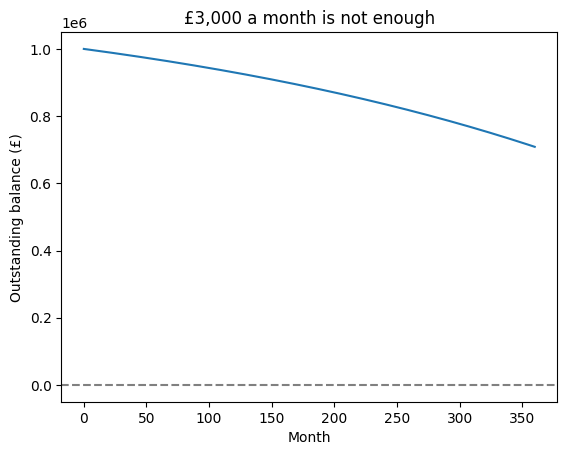

In [ ]:
plt.figure()
plt.plot(history)
plt.axhline(0, color="grey", linestyle="--")
plt.xlabel("Month")
plt.ylabel("Outstanding balance (£)")
plt.title("£3,000 a month is not enough")
plt.show()

We could keep guessing, but there is a smarter way: **binary search**. Keep a low guess
and a high guess, test the midpoint by running the simulation, and throw away the half of
the range the answer cannot be in. Each test halves the search space, so 30 tests get you
to the penny.

This pattern — wrap the simulation in a function, then search over its input — is worth
remembering. It generalises to any "what parameter value produces this outcome?" question.

In [ ]:
# a function to compute the balance after 30 years, for a given payment

def mortgage_balance(payment):
    balance = principal
    for month in range(n_month):
        balance = balance + balance * monthly_rate
        balance = balance - payment
    return balance


# binary search for the monthly payment
low = 3000
high = 1000000   # = principal: the payment is certainly below this

while high - low > 0.01:   # run until the gap is under a penny
    mid = (low + high) / 2
    balance = mortgage_balance(mid)

    if balance > 0:   # payment too small: debt remains
        low = mid
    else:             # payment too big: overpaid
        high = mid

print(f"Required monthly payment: £{round(high, 2):,}")

Required monthly payment: £4,216.05


### Exercise 1

Compute the monthly payment for properties priced at £750,000, £500,000 and £250,000.

*Hint*: `mortgage_balance` currently reads `principal` from outside the function. Give it
a second argument instead, so the same function works for any price.

In [ ]:
# your answer here
# hint: def mortgage_balance2(payment, principal): ...


price = [1000000, 750000, 500000, 25000]


### Exercise 2a

A customer says: "I can only afford £3,500 a month — how many years do I need?"

*Hint*: this is a `while` loop, not a `for` loop. You do not know the number of months in
advance; you know the stopping condition. Create a function to compute the number of months one needs to pay off the debt where you put payment as an argument.


In [ ]:
# your answer here


### Exercise 2b

Write a function that takes the principal, the annual interest rate and the monthly
payment as inputs and returns the number of years required to repay the loan in full.

*Hint*: some payments never repay the loan, because the payment is smaller than the
interest accruing each month. Guard against that before you enter the loop, or the cell
will run forever.

In [ ]:
# your answer here


---

# Monte Carlo estimation

**Scenario**: the Monte Carlo method generates huge numbers of random examples and counts
how often an event happens. The proportion in the sample estimates the probability in the
world.

The classic demonstration is estimating π. Throw darts uniformly at a 2 × 2 square. A
circle of radius 1 inscribed in that square has area π; the square has area 4; so the
fraction of darts landing inside the circle estimates π/4.

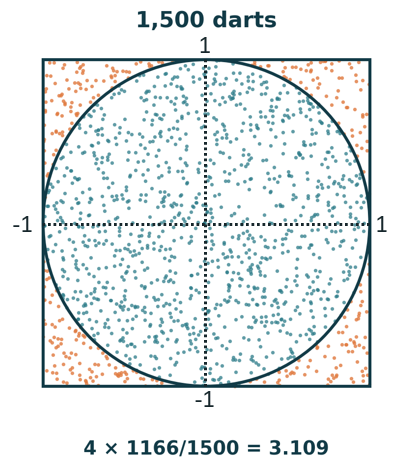

In [ ]:
def estimate_pi(n_darts):
    inside = 0
    for i in range(n_darts):
        x = random.random() * 2 - 1   # ranges from -1 to 1
        y = random.random() * 2 - 1   # ranges from -1 to 1
        if x ** 2 + y ** 2 < 1:       # area inside the circle
            inside += 1
    return 4 * inside / n_darts # 4 = the square


for n in [10, 100, 1000, 10000, 100000, 1000000]:
    print(f"{n:>8} darts -> pi is about {estimate_pi(n):.5f}")

      10 darts -> pi is about 3.60000
     100 darts -> pi is about 3.16000
    1000 darts -> pi is about 3.04400
   10000 darts -> pi is about 3.15240
  100000 darts -> pi is about 3.13936
 1000000 darts -> pi is about 3.14175


The last line takes a few seconds — a million darts in pure Python is slow. Watch the
error shrink: accuracy improves with the *square root* of the sample size, so ten times
more darts buys you roughly three times less error. That is the fundamental economics of
Monte Carlo, and it is why simulation studies need large numbers of runs.



Now the **birthday problem**: how many people must be in a room before there is a
better-than-even chance that some two of them share a birthday? Let's simulate rooms.

In [ ]:
def random_room(n_people):
    birthdays = [random.randint(1, 365) for _ in range(n_people)]
    return len(set(birthdays)) < len(birthdays) # True if the condition is met
    # set() removes duplicates; if the set is smaller than the list,
    # the list contained duplicates


sizes = [10, 20, 30, 40, 50, 60]
trials = 10000
probs = []

for n in sizes:
    hits = sum(random_room(n) for _ in range(trials))# n of Trues we get out of 10000 trials
    p = hits / trials
    probs.append(p)
    print(f"With {n} people in a room, P(some two share a birthday) = {p:.2f}")

With 10 people in a room, P(some two share a birthday) = 0.12
With 20 people in a room, P(some two share a birthday) = 0.41
With 30 people in a room, P(some two share a birthday) = 0.70
With 40 people in a room, P(some two share a birthday) = 0.89
With 50 people in a room, P(some two share a birthday) = 0.97
With 60 people in a room, P(some two share a birthday) = 0.99


Two idioms worth pausing on. `_` is a conventional name for a loop variable you never
use. And `sum()` over a sequence of booleans counts the `True`s, because `True` behaves
as 1 — so `sum(random_room(n) for _ in range(trials))` is "how many of these rooms had a
match".

That does not yet answer the question, which was about the 50% threshold. Let's use a
`while` loop to walk up until the probability exceeds 0.5.

In [ ]:
n = 2
while True:   # keep looping until we explicitly stop with "break"
    hits = sum(random_room(n) for _ in range(trials))
    p = hits / trials

    if p > 0.5:
        print(f"{n} people: P = {p:.3f}")
        break

    n += 1

23 people: P = 0.502


### Exercise 3a

How does the birthday answer change on a planet with 600-day years?

*Hint*: generalise `random_room` so that the length of the year is an argument.

In [ ]:
# your answer here

---

# Retail

**Scenario**: a fish and chips shop owner wants to use fresh cod. The owner goes to the
market every morning and buys cod for the day. Fresh fish does not keep — whatever is not
sold by closing goes in the bin (I know… not sustainable; let's say the owner donates the
leftovers to a cat sanctuary). So the owner makes one big decision every day: how many cod
to buy.

Four important numbers:

1. A cod costs **£15** at the market and yields about three servings, which sell for £45.
   Each cod the owner sells therefore contributes **£30**.
2. Each cod the owner buys and does not sell is a straight **£15 loss**.
3. Running out is worse than either. Some people who wanted fish and chips go to the kebab
   shop instead, and may not come back for a long time. Say that for each portion of
   **unmet demand** the owner loses a further **£10** in goodwill.
4. Demand averages 40 cod a day and fluctuates roughly between 32 and 50.

Buy too few and you turn away money. Buy too many and you are feeding cats. This is the
**newsvendor problem** — named for the paper seller whose stock is worthless by evening —
and it is among the most-studied models in operations research, because so many businesses
live inside it: bakeries, florists, airlines pricing seats, hospitals booking theatre
slots, festivals ordering wristbands.

Let's create a function that computes the average daily profit for a given order size.

In [ ]:
cost, price, goodwill = 15, 45, 10


def chippy_run(order, days=10000, mean_demand=40, sd_demand=6):# order = cod you buy
    total = 0 # profit
    for _ in range(days):
        demand = int(np.random.normal(mean_demand, sd_demand))
        demand = max(demand, 0)     # demand cannot be negative
        sold = min(order, demand)   # you cannot sell fish you did not buy
        short = demand - sold       # fish you could have sold
        revenue = sold * price
        spend = order * cost
        total += revenue - spend - short * goodwill
    return total / days


Note that `chippy_run` reads `cost`, `price` and `goodwill` from outside itself. That is
convenient for teaching but fragile: change `cost` anywhere in the notebook and every
later call to `chippy_run` silently changes too. Keep it in mind when you get to
Exercise 4a.

Now compute the average daily profit across a range of order sizes:

In [ ]:
orders = range(20, 71)
profits = [chippy_run(o) for o in orders]

best_i = profits.index(max(profits))   # the position of the best profit
print(f"The optimal order is {orders[best_i]} cod, "
      f"with an expected profit of £{profits[best_i]:,.2f} a day.")

The optimal order is 43 cod, with an expected profit of £1,074.63 a day.


The whole profit curve is more informative than the single best point:

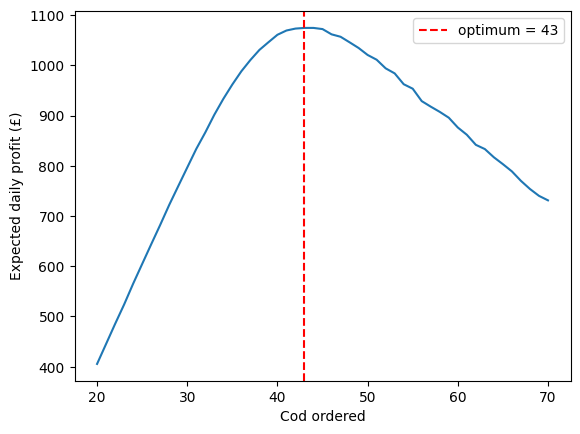

In [ ]:
plt.figure()
plt.plot(list(orders), profits)
plt.axvline(orders[best_i], color="red", linestyle="--",
            label=f"optimum = {orders[best_i]}")
plt.xlabel("Cod ordered")
plt.ylabel("Expected daily profit (£)")
plt.legend()
plt.show()

Notice how flat the curve is near the top, which is a genuinely useful managerial finding: the owner does not need to get this
exactly right.

### Exercise 4a

The price of cod goes up and it is now £25. The owner wants to keep menu prices the same.
What is the best order now?

*Hint*: remember that `chippy_run` reads `cost` from the surrounding session.

In [ ]:
# your answer here


---

# Queues

**Scenario**: the same fish and chips shop now has a different problem. The owner sees a queue out
of the door. The owner can put more staff on the counter, but each one costs a shift. Too
few and customers wait, get angry, and drift off to the kebab shop. Too many and the owner
is paying people to stand about. How many should the owner hire?

To simplify, assume each member of staff does the whole job for one customer. One person
serves one customer at a time, and there is a single queue that whoever is free takes from
next.

Two things are random:

1. customers arrive every 10 minutes on average — sometimes three walk in together,
   sometimes nobody comes for 20 minutes;
2. serving one customer takes 10 minutes on average.

You do not simulate every minute. You only track, for each member of staff, the time they
will next be free. When a customer walks in, three questions settle everything:

1. who is free to serve soonest?
2. when does this customer actually start getting served — when they arrive, or when the
   next server becomes available?
3. when is that server free again (start time + serving time)?

This is called a **discrete-event** simulation: the clock jumps from event to event rather
than ticking uniformly. It is dramatically more efficient than stepping through minutes.

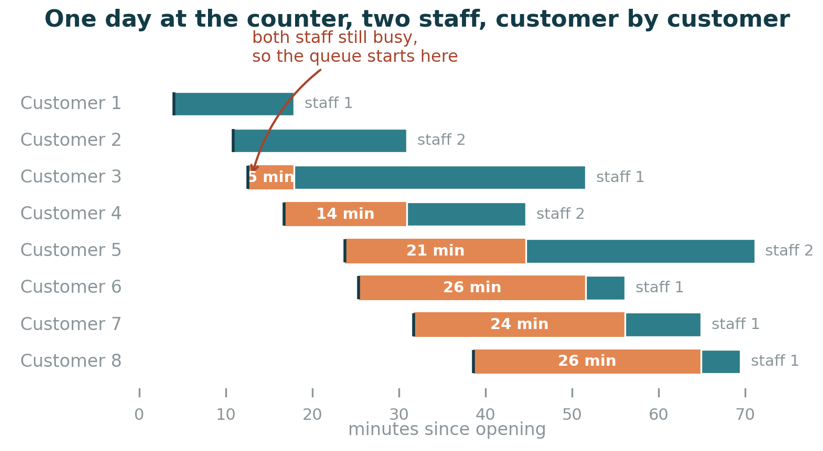

In [ ]:
mean_gap = 10       # average minutes between customer arrivals
mean_service = 10   # average serving time
minutes = 60 * 12   # the shop is open from 10am to 10pm
days = 200          # simulating 200 days

for staff in range(1, 7):
    random.seed(5)   # same arrival stream for every staffing level
    waits = []

    for d in range(days):
        free_at = [0.0] * staff
        clock = 0

        while clock < minutes:
            # arrivals follow the exponential distribution - the standard choice
            # for "time until the next random event"
            clock += random.expovariate(1 / mean_gap)   # the next customer walks in
            earliest = min(free_at)                     # who is free soonest?
            counter = free_at.index(earliest)           # which member of staff?
            start = max(clock, earliest)                # when do they get served? whichever is later.
            free_at[counter] = start + random.expovariate(1 / mean_service) # updating staff availability (i.e., the staff member is busy until....). expovariate takes the rate of the exponential dist (x arrival per min).
            # expovariate here is a bit questionable to be honest
            waits.append(start - clock)                 # wait time

    average = sum(waits) / len(waits)
    longest = max(waits)
    print(f"{staff} staff: average wait {average:7.2f} mins; worst wait {longest:8.2f} mins")

1 staff: average wait   58.15 mins; worst wait   404.12 mins
2 staff: average wait    3.16 mins; worst wait    68.54 mins
3 staff: average wait    0.44 mins; worst wait    28.25 mins
4 staff: average wait    0.07 mins; worst wait    16.72 mins
5 staff: average wait    0.01 mins; worst wait     8.31 mins
6 staff: average wait    0.00 mins; worst wait     4.99 mins


Look at the one-staff row. With arrivals every 10 minutes on average and service taking
10 minutes on average, a single server is working flat out, and the average wait is around
an hour. This is not a bug. A queue whose arrival rate equals its service capacity has no
stable equilibrium: it builds all day and never clears. The only reason the numbers here
are finite is that `free_at` resets every morning, so the 12-hour day caps how bad it can
get. Lengthen the day and the one-staff waits get worse without limit.

The practical lesson is the size of the jump from 1 to 2 to 3. Adding a little slack
capacity buys an enormous reduction in waiting. That non-linearity is why understaffing
fails so badly and so suddenly.

Note also `random.seed(5)` inside the loop: it gives every staffing level the same stream
of customers, so we are comparing staffing rather than luck. Holding the random stream
fixed across conditions is called **common random numbers**, and it is a standard way to
reduce noise in simulation comparisons.

### Exercise 5a

Something has happened and demand has doubled: customers now arrive every 5 minutes. How
many staff should the owner employ?

In [ ]:
# your answer here



---

# Hiring

**Scenario**: you are hiring for one position and interviewing candidates one at a time.
After each interview you must decide immediately — hire this person and stop, or reject
them and see the next. You can rank the candidates you have seen against each other, but
you cannot see the future. With 40 applicants, what strategy gives you the best shot at
landing the very best one?

This is the **secretary problem**, or optimal stopping problem. The hiring version is not
very realistic in academia, but the same structure appears elsewhere: choosing a flat in a
hot market (like London), picking a petrol station on a motorway, deciding when to stop
reading reviews and just book the restaurant.

There is a startlingly clean answer: reject the first 37% of candidates no matter what,
purely to calibrate. Then hire the first subsequent candidate who beats everyone you have
seen so far. The 37% is 1/e ≈ 0.368. Let's verify it.

In [ ]:
def hiring_run(n, look_fraction):
    candidates = [i for i in range(n)]   # 0 = the best candidate, n-1 = the worst
    random.shuffle(candidates)           # randomise arrival order
    look = int(n * look_fraction)        # how many you reject out of hand
    best_seen = float("inf")             # nothing seen yet

    for i in range(look):                # calibration stage
        best_seen = min(best_seen, candidates[i])

    for i in range(look, n):             # hiring stage
        if candidates[i] < best_seen:
            return candidates[i]

    return candidates[-1]                # nobody beat it -> forced to take the last one


n = 40
trials = 20000
wins = sum(hiring_run(n, 0.37) == 0 for _ in range(trials))   # rank 0 = the best
print(f"The 37% rule catches the #1 candidate {wins / trials:.1%} of the time")

The 37% rule catches the #1 candidate 37.7% of the time


About 37% — the success rate happens to match the look fraction, which is not a
coincidence but is a nice mnemonic. It is impressive that you can get the single best
person out of 40 candidates well over a third of the time, given how little information
the rule uses.

Let's confirm 37% is optimal by sweeping the whole range:

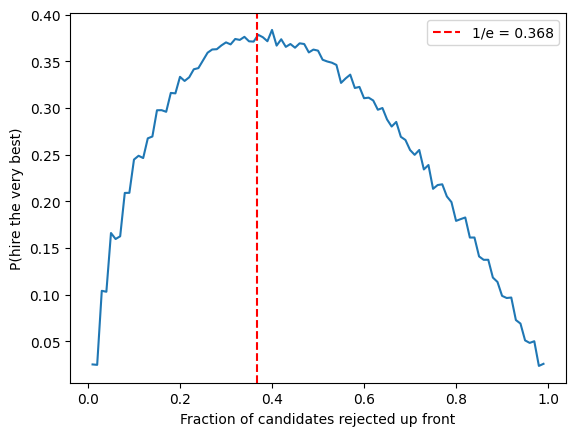

In [ ]:
fractions = [i / 100 for i in range(1, 100)]
success = []
for f in fractions:
    wins = sum(hiring_run(40, f) == 0 for _ in range(20000))
    success.append(wins / 20000)

plt.figure()                                       # a fresh sheet of paper
plt.plot(fractions, success)                       # fraction on x, success on y
plt.axvline(1 / np.e, color="red", linestyle="--", label="1/e = 0.368")
plt.xlabel("Fraction of candidates rejected up front")
plt.ylabel("P(hire the very best)")
plt.legend()
plt.show()                                         # display the figure

The peak sits right at 0.37 — the simulation has rediscovered a theorem. This is a good
sanity check to keep in mind: when you can validate a simulation against a known
analytical result, do it, because it catches implementation errors that no amount of
staring at plausible-looking output will.

### Exercise 6a

The 37% rule maximises the chance of getting the single best applicant. But it treats hiring the second-best exactly the same as hiring the worst, which is a strange thing to want.

Suppose instead you care about the rank of the person you end up with: hiring the 3rd best out of 40 is a good outcome, hiring the 31st is not. For each look fraction, compute the average rank of the person hired, and plot it. Where is the minimum, and how does it compare with 0.37?

Hint: hiring_run already returns the rank of the person hired, where 0 is the best. You do not need to change the function at all — you only need to change its output.

In [ ]:
# your answer here



---

# Public health and marketing

**Scenario**: an epidemiologist wants to know how far an outbreak will spread and how
fast. A product manager wants to know how quickly a new app will be adopted. These sound
like different problems, but they are nearly the same and we can model them the same way.

One of the epidemiologists' classic tools is the **SIR model**, which splits a population
into three groups: **S**usceptible (can catch it), **I**nfectious (has it and spreads it),
and **R**ecovered (immune or removed). People flow S → I → R over time. The model is a set
of rules about rates of flow. (S, I and R are head counts.)

The S → I flow needs two people. An infection requires a
susceptible person and an infectious person to come together. If 4 susceptible and 3
infectious people are milling about, there are 4 × 3 = 12 pairs where the disease could
pass. Double the infectious and you get 24 pairs; double both and you get 48. The
opportunities scale with the **product**, not the sum. So S × I counts the pairs where the
disease could spread. But not every such pair actually meets, and not every meeting passes
the infection on — which is what β is for.

β is a lump sum: **contact rate × transmission probability**. Two quite separate things
rolled into one constant — how often a given pair comes into contact, and how likely the
disease is to spread when they do. (Yes, this is very simple, and you can think of it as
one limitation.) New infections per period can then be written as β × S × I.

Keeping those two ingredients in view explains a lot. Lockdowns do not change the virus —
they cut the contact rate (one part of β). Masks and ventilation cut the transmission
probability (the other part). The effectiveness of lockdown and mask policies depends on
how much they reduce β, and the same policy may reduce β differently in different
societies.

One of the biggest simplifications is worth flagging: because the contact rate is a single
fixed average, the model assumes everyone mixes with everyone equally, which is pretty
unrealistic. We relax that later.

The I → R flow needs only one person — recovering does not require bumping into anybody.
Each infectious person simply gets better at some rate. If γ = 0.1, then 10% of the
infectious recover each period, whatever everyone else is doing. So recoveries per period
are γ × I.

Do you start to see a model? Let's build it with these assumptions: every person meets 3
others per day; a 10% transmission probability per contact; 10 out of 1,000 people in a
town have contracted a new virus; the recovery rate is 10% per day.

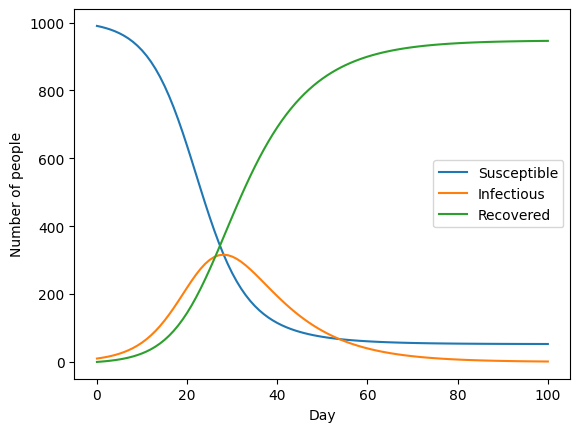

Peak infections: 315.94 people, on day 28
Never infected at all: 52.82 people


In [ ]:
# the infected town
S, I, R = 990, 10, 0   # 10 infections in a town of 1000 people
n = S + I + R

# parameters
contact_per_day = 3         # each person meets 3 others per day
transmission_prob = 0.1     # 10% chance of passing it on per S-I contact
beta = contact_per_day * transmission_prob / n   # infection rate per S-I pair per day
# new infections = I x contact_per_day × (S / n = prob that a person you meet is S) × transmission_prob (new infections = beta x I x S)
gamma = 0.1                 # 10% of I recover each day
days = 100

# the head counts of S, I and R over time
S_history = [S]
I_history = [I]
R_history = [R]

# simulation
for day in range(days):
    new_infections = beta * S * I
    new_recoveries = gamma * I

    S = S - new_infections
    I = I + new_infections - new_recoveries
    R = R + new_recoveries

    S_history.append(S)
    I_history.append(I)
    R_history.append(R)

# plotting
plt.figure()
plt.plot(S_history, label="Susceptible")
plt.plot(I_history, label="Infectious")
plt.plot(R_history, label="Recovered")
plt.xlabel("Day")
plt.ylabel("Number of people")
plt.legend()
plt.show()

print(f"Peak infections: {max(I_history):.2f} people, on day {I_history.index(max(I_history))}")
print(f"Never infected at all: {S_history[-1]:.2f} people")



The epidemic peaks around day 28 and then declines without any intervention at all,
leaving a residue of people who were never infected. That decline is **herd immunity**
emerging: as S shrinks, β × S × I falls, and eventually each infectious person infects
fewer than one other before recovering.

In this model an infectious person meets 3 others every day, infects 10% of them, and
stays infectious for 1/γ = 10 days. So 3 × 0.1 × 10 = 3 new infections per case. This
number is the **basic reproduction number**, R₀. When R₀ < 1 the outbreak dies out; when
R₀ > 1 it grows. An R₀ of around 3 is in the range of published estimates for ancestral
SARS-CoV-2 — do check the current literature rather than taking that from a workshop
notebook.

Now let's consider some interventions:

* **Lockdown**: halve contacts.
* **Mask mandate**: halve transmission.
* **Both**: halve both.

In [ ]:
for label, contacts, transmission in [
        ("No action",                  3,   0.1),
        ("Halve contacts (lockdown)",  1.5, 0.1),
        ("Halve transmission (masks)", 3,   0.05),
        ("Both",                       1.5, 0.05)]:
        # a list of tuples representing the four scenarios

    beta = contacts * transmission / n
    S, I, R = 990, 10, 0
    I_history = [I]   # we only track the infectious this time

    for day in range(days):
        new_infections = beta * S * I
        new_recoveries = gamma * I
        S = S - new_infections
        I = I + new_infections - new_recoveries
        R = R + new_recoveries
        I_history.append(I)

    R0 = contacts * transmission / gamma

    print(f"{label:30s} R0={R0:.2f}: peak = {max(I_history):5.0f} "
          f"on day {I_history.index(max(I_history))}")

No action                      R0=3.00: peak =   316 on day 28
Halve contacts (lockdown)      R0=1.50: peak =    71 on day 66
Halve transmission (masks)     R0=1.50: peak =    71 on day 66
Both                           R0=0.75: peak =    10 on day 0


Halving contacts and halving transmission have identical effects here, because β is their
product — the model cannot tell them apart. That is a feature of this level of abstraction
and a limitation to state plainly when you report results from it.

Now some exercises, taken from the perspective of the new disease — our goal is to infect
everyone.

### Exercise 7a

Keep contacts at 3 per day and sweep `transmission_prob` over 0.1, 0.2, 0.3, 0.4 and 0.5.
Report R₀ for each, and interpret the results.

*Hint*: with a high β, `beta * S * I` can exceed the number of susceptible people
remaining, which would drive S negative. Cap it with `min(beta * S * I, S)`.

In [ ]:
# your answer here

### Exercise 7b

The virus goes deadly. So far everyone eventually recovers. Add a fourth compartment,
**D**ead, so that people flow S → I → then R or D. Sweep transmission over
[0.1, 0.3, 0.5] and the case fatality rate over [0.05, 0.1, 0.3].

*Hint*: split γ into a recovery rate and a death rate that sum to γ, so that the total
outflow from I is unchanged.

In [ ]:
# your answer here

---

## Agent-based modelling

Finally, agent-based modelling.

An **agent-based model** builds the population out of individuals. Each one is an object
with its own state, and infection happens when two specific individuals meet.

Let's replicate the previous simulation as an ABM. We represent each person as an `Agent`
carrying a single piece of state: S = 0, I = 1, R = 2. Using numbers rather than strings
is the convention in this literature and makes counting easy.

`infect()` and `recover()` are **methods** — actions an agent performs on itself.

In [ ]:
class Agent:
    def __init__(self, status):
        self.status = status   # S = 0, I = 1, R = 2

    def infect(self):
        self.status = 1        # S -> I

    def recover(self):
        self.status = 2        # I -> R


def count_status(population):
    # count how many agents are in each of the three states
    counts = [0, 0, 0]
    for a in population:
        counts[a.status] += 1
    return counts

Previously we calculated β × S × I — how many infections happen in aggregate. Now we loop
over every infectious agent, pick their contacts one at a time, and roll a die for each.

The equation model is **deterministic**: no randomness is involved, so β × S × I computes
the same value every time and running it twice gives identical results. One run of 365
days is enough.

The agent model is **stochastic**. Every contact is random and every transmission is
random, so each run is a different epidemic. That changes what counts as a result: a
single run tells you almost nothing, and you have to run it many times and report the
distribution.

In [ ]:
def one_run(n=1000, contacts=3, transmission=0.1, gamma=0.1,
            days=150, init_I=10):

    population = []
    for i in range(n):
        # a population with init_I infected people to start with
        population.append(Agent(1) if i < init_I else Agent(0))

    history = [count_status(population)]

    for day in range(days):
        newly_infected = []
        for agent in population:
            if agent.status == 1:               # infectious agents infect others
                for c in range(contacts):
                    other = random.choice(population)
                    if other.status == 0 and random.random() < transmission:
                        newly_infected.append(other)

        newly_recovered = []
        for agent in population:                # infectious agents recover
            if agent.status == 1 and random.random() < gamma:
                newly_recovered.append(agent)

        # apply all changes at the end of the day
        for a in newly_infected:
            a.infect()
        for a in newly_recovered:
            a.recover()

        history.append(count_status(population))

    return history

One design detail is worth dwelling on, because it is the most common source of subtle
bugs in ABMs. Notice that we collect `newly_infected` and `newly_recovered` in lists and
only apply them **after** the loop over the population has finished. If we infected agents
immediately, an agent infected early in the day could go on to infect others *the same
day*, and — worse — the outcome would depend on the arbitrary order of the population
list. Separating "decide" from "update" is called **synchronous updating**, and whether you
use it is a substantive modelling choice that should be reported.

(An aside: agents can also contact themselves here, since `random.choice(population)` can
return the agent doing the contacting. With n = 1000 that is a 0.1% effect. Worth knowing
it is there.)

Now run it 100 times and average the peak size and peak day.

This cell takes a minute or two: 100 runs x 150 days x 1,000 agents is around 15 million
operations in pure Python. Agent-based models are expensive, which is why the horizon is
150 days here rather than 365 - the epidemic is long over by then. If you are short of
time, pass `days=100` or use `range(30)` instead of `range(100)`.

In [ ]:
peaks = []
peak_days = []
escaped = []

for run in range(100):
    h = one_run()
    I = [day[1] for day in h]
    S = [day[0] for day in h]
    peaks.append(max(I))
    peak_days.append(I.index(max(I)))
    escaped.append(S[-1])

print(f"mean peak: {sum(peaks) / len(peaks):.0f} "
      f"on day {sum(peak_days) / len(peak_days):.0f}; "
      f"mean escaped: {sum(escaped) / len(escaped):.0f}")
print(f"peak ranged from {min(peaks)} to {max(peaks)} across the 100 runs")

mean peak: 313 on day 29; mean escaped: 59
peak ranged from 247 to 365 across the 100 runs


That range is the point. Reporting only the mean of a stochastic model hides how much any
single run can differ, so plot the runs:

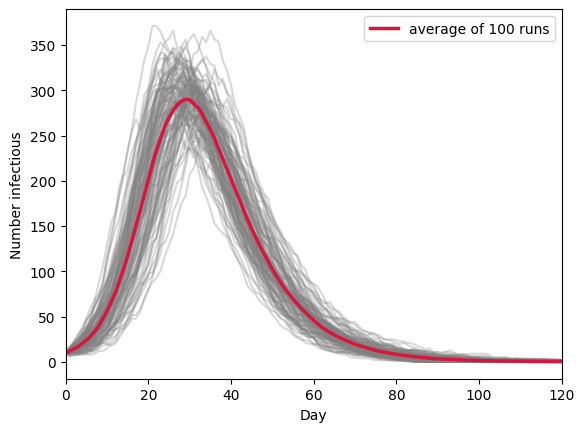

In [ ]:
all_I = []

for run in range(100):
    h = one_run()
    I = [day[1] for day in h]
    all_I.append(I)

ave_I = []
for day in range(len(all_I[0])):
    total = 0
    for I in all_I:
        total = total + I[day]
    ave_I.append(total / len(all_I))

plt.figure()
for I in all_I:
    plt.plot(I, color="grey", alpha=0.3)
plt.plot(ave_I, color="crimson", linewidth=2.5, label="average of 100 runs")
plt.xlabel("Day")
plt.ylabel("Number infectious")
plt.xlim(0, 120)
plt.legend()
plt.show()

Every run takes off here — with 10 people infectious at the start and R₀ = 3, stochastic
extinction is effectively impossible. (Set `init_I=1` and you will see some outbreaks die
immediately; that is worth trying.) What varies is the size and timing of the peak.

The more important thing in this figure is the crimson average curve, which is lower and
broader than any individual epidemic. That is not because the average epidemic is milder;
it is because the peaks do not line up in time, so averaging across runs that peak on
different days smears them into a shape no single run resembles. **The mean trajectory is
not a typical trajectory.** This is a general hazard when summarising stochastic models —
if you need a summary, the distribution of peak size and peak day is more honest than the
mean curve.

Agent-based approaches earn their cost when what you want to examine depends on
individuals differing from each other, or on luck. For instance, I am the type who meets
about three people a day, but others meet 50 (clubbing every night). We can model that
kind of individual difference as a property of the agent.

In [ ]:
class Agent:
    def __init__(self, status, contacts):
        self.status = status
        self.contacts = contacts   # number of contacts is now a property

    def infect(self):
        self.status = 1

    def recover(self):
        self.status = 2


def one_run2(prop_social=0.5, social=50, nonsocial=3,
             n=1000, transmission=0.1, gamma=0.1, days=150, init_I=10):

    population = []
    for i in range(n):
        if random.random() < prop_social:
            c = social        # a sociable person
        else:
            c = nonsocial     # a quiet one
        population.append(Agent(1 if i < init_I else 0, c))

    history = [count_status(population)]

    for day in range(days):
        newly_infected = []
        for agent in population:
            if agent.status == 1:
                for k in range(agent.contacts):
                    other = random.choice(population)
                    if other.status == 0 and random.random() < transmission:
                        newly_infected.append(other)

        newly_recovered = []
        for agent in population:
            if agent.status == 1 and random.random() < gamma:
                newly_recovered.append(agent)

        for a in newly_infected:
            a.infect()
        for a in newly_recovered:
            a.recover()

        history.append(count_status(population))

    return history

Note that redefining `class Agent` in that cell has **replaced** the earlier one. If you
now re-run the `one_run()` cell above, it will fail, because `Agent(1)` no longer accepts
a single argument. This is the single most common Colab confusion: cells share one session,
so the state of your notebook depends on execution order, not on what you see on screen.
When results stop making sense, **Runtime → Restart session and run all**.

Mean contacts here are 0.5 × 50 + 0.5 × 3 = 26.5 a day, far above the 3 in the homogeneous
model, so expect a much faster and larger epidemic.

In [ ]:
peaks = []
peak_days = []
escaped = []

for run in range(100):
    h = one_run2()
    I = [day[1] for day in h]
    S = [day[0] for day in h]
    peaks.append(max(I))
    peak_days.append(I.index(max(I)))
    escaped.append(S[-1])

print(f"mean peak: {sum(peaks) / len(peaks):.0f} "
      f"on day {sum(peak_days) / len(peak_days):.0f}; "
      f"mean escaped: {sum(escaped) / len(escaped):.0f}")
print(f"peak ranged from {min(peaks)} to {max(peaks)}; "
      f"peak day from {min(peak_days)} to {max(peak_days)}")

mean peak: 833 on day 5; mean escaped: 0
peak ranged from 804 to 867; peak day from 4 to 6


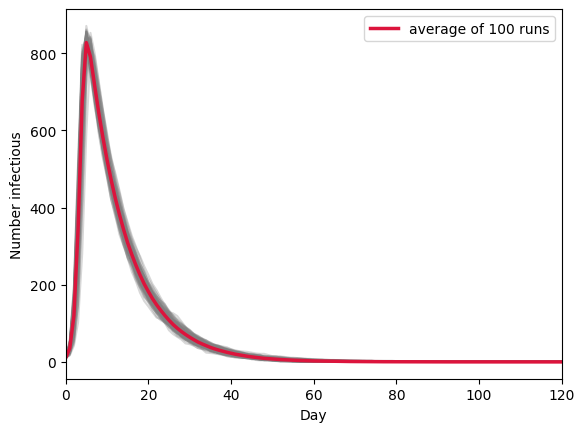

In [ ]:
all_I = []

for run in range(100):
    h = one_run2()
    I = [day[1] for day in h]
    all_I.append(I)

ave_I = []
for day in range(len(all_I[0])):
    total = 0
    for I in all_I:
        total = total + I[day]
    ave_I.append(total / len(all_I))

plt.figure()
for I in all_I:
    plt.plot(I, color="grey", alpha=0.3)
plt.plot(ave_I, color="crimson", linewidth=2.5, label="average of 100 runs")
plt.xlabel("Day")
plt.ylabel("Number infectious")
plt.xlim(0, 120)
plt.legend()
plt.show()

Heterogeneity in contact rates changes the epidemic qualitatively, not just
quantitatively: it is faster, larger, and far more consistent across runs. And critically,
you could not have got here from the equation model, because the equation model has only
the *mean* contact rate to work with. That is the case for agent-based modelling in one
figure.

Something to try if you have time: set `prop_social=0.05, social=500` so that the mean
contact rate is roughly unchanged but the variance is enormous. The mean is not what drives
the outbreak.

---

# Answers

Each answer is hidden. Click **Show code** on a cell to reveal it, then run it.

Two warnings. These cells assume the imports at the top of the notebook have been run.
And some of them deliberately change shared variables (`cost`, `mean_gap`) and then change
them back — read the comments.

In [ ]:
#@title Exercise 1 - payments for different property prices { display-mode: "form" }

# take the principal as an argument instead of reading it from outside
def mortgage_balance2(payment, principal):
    balance = principal
    for month in range(n_month):
        balance = balance + balance * monthly_rate
        balance = balance - payment
    return balance


prices = [1000000, 750000, 500000, 250000]

for p in prices:
    low = 0
    high = p

    while high - low > 0.01:
        mid = (low + high) / 2
        balance = mortgage_balance2(mid, p)

        if balance > 0:
            low = mid
        else:
            high = mid

    print(f"Property price £{p}  ->  monthly payment £{high:,.2f}")


Property price £1000000  ->  monthly payment £4,216.05
Property price £750000  ->  monthly payment £3,162.03
Property price £500000  ->  monthly payment £2,108.02
Property price £250000  ->  monthly payment £1,054.01


In [ ]:
#@title Exercise 2a - how many years at £3,500 a month { display-mode: "form" }

def months_to_payoff(payment):
    balance = principal
    month = 0

    while balance > 0:
        balance = balance + balance * monthly_rate
        balance = balance - payment
        month += 1
    return month


m = months_to_payoff(3500)
print(f"{m} months = {m / 12:.1f} years")

502 months = 41.8 years


In [ ]:
#@title Exercise 2b - a general years_to_payoff function { display-mode: "form" }

def years_to_payoff(principal, annual_rate, payment):
    monthly_rate = annual_rate / 12

    # guard first: if the payment does not even cover the first month's interest, the balance grows every month and the loop would never end
    if payment <= principal * monthly_rate:
        return "payment too small"

    balance = principal
    month = 0
    while balance > 0:
        balance = balance + balance * monthly_rate - payment
        month += 1

    return month / 12


print(years_to_payoff(1000000, 0.03, 4216))   # ~30 years
print(years_to_payoff(1000000, 0.03, 6000))   # faster
print(years_to_payoff(1000000, 0.03, 2000))   # None: never repaid

30.083333333333332
18.0
payment too small


In [ ]:
#@title Exercise 3a - birthdays on a 600-day planet { display-mode: "form" }

def random_room2(n_people, year_length):
    birthdays = [random.randint(1, year_length) for _ in range(n_people)]
    return len(set(birthdays)) < len(birthdays)


trials = 10000

for year_length in [365, 600]:
    n = 2
    while True:
        hits = sum(random_room2(n, year_length) for _ in range(trials))
        p = hits / trials
        if p > 0.5:
            print(f"{year_length}-day year: {n} people (P = {p:.3f})")
            break
        n += 1

# the threshold grows with the square root of the year length,
# so 600/365 = 1.64 times more days needs only sqrt(1.64) = 1.28 times more people

365-day year: 23 people (P = 0.504)
600-day year: 29 people (P = 0.501)


In [ ]:
#@title Exercise 4a - cod now costs £25 { display-mode: "form" }

# chippy_run reads `cost` from the surrounding session, so we change it,
# run the sweep, and then change it back
cost = 25

orders = range(10, 71)
profits = [chippy_run(o) for o in orders]
best_i = profits.index(max(profits))
print(f"At £25 per cod: optimal order {orders[best_i]} cod, "
      f"expected profit £{profits[best_i]:,.2f} a day")

cost = 15   # restore, so later cells are not silently affected
print("cost restored to", cost)

# the optimal order falls: each unsold fish now costs more, so the owner
# hedges less against running out

At £25 per cod: optimal order 40 cod, expected profit £658.95 a day
cost restored to 15


In [ ]:
#@title Exercise 5a - demand doubles { display-mode: "form" }

# set every parameter explicitly - the SIR section later in the notebook
# reassigns `days`, so inheriting it here would be a silent bug
mean_gap = 5        # customers now arrive every 5 minutes
mean_service = 10
minutes = 60 * 12
days = 200

for staff in range(1, 7):
    random.seed(5)   # common random numbers across staffing levels
    waits = []
    for d in range(days):
        free_at = [0.0] * staff
        clock = 0
        while clock < minutes:
            clock += random.expovariate(1 / mean_gap)
            earliest = min(free_at)
            counter = free_at.index(earliest)
            start = max(clock, earliest)
            free_at[counter] = start + random.expovariate(1 / mean_service)
            waits.append(start - clock)
    average = sum(waits) / len(waits)
    longest = max(waits)
    print(f"{staff} staff: average wait {average:7.2f} mins; worst wait {longest:8.2f} mins")

mean_gap = 10   # restore
print("\nmean_gap restored to", mean_gap)

# with arrivals every 5 mins and 10-min service, the shop needs at least
# 2 staff just to keep up, and 3 before waits become tolerable

1 staff: average wait  370.79 mins; worst wait  1207.58 mins
2 staff: average wait   41.23 mins; worst wait   256.04 mins
3 staff: average wait    4.33 mins; worst wait    80.93 mins
4 staff: average wait    0.86 mins; worst wait    33.71 mins
5 staff: average wait    0.19 mins; worst wait    19.61 mins
6 staff: average wait    0.04 mins; worst wait    12.56 mins

mean_gap restored to 10


lowest average rank 4.82 at a look fraction of 14%
at the famous 37%, the average rank is 7.56


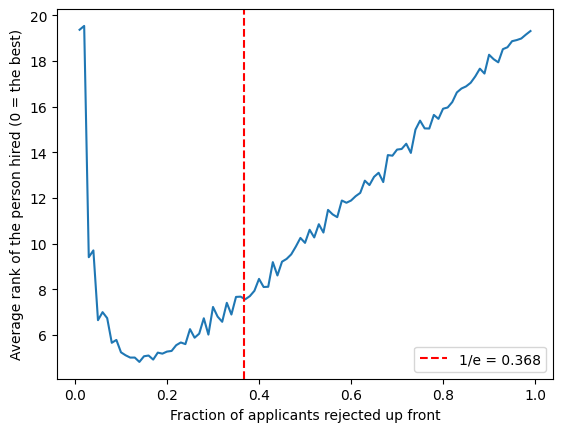

In [ ]:
#@title Exercise 6a - happy with either of the top 2 { display-mode: "form" }

n = 40
trials = 4000
fractions = [i / 100 for i in range(1, 100)]

mean_rank = []
for f in fractions:
    runs = [hiring_run(n, f) for _ in range(trials)]
    mean_rank.append(sum(runs) / trials)

best_i = mean_rank.index(min(mean_rank))
print(f"lowest average rank {min(mean_rank):.2f} at a look fraction of {fractions[best_i]:.0%}")
print(f"at the famous 37%, the average rank is {mean_rank[fractions.index(0.37)]:.2f}")

plt.figure()
plt.plot(fractions, mean_rank)
plt.axvline(1 / np.e, color="red", linestyle="--", label="1/e = 0.368")
plt.xlabel("Fraction of applicants rejected up front")
plt.ylabel("Average rank of the person hired (0 = the best)")
plt.legend()
plt.show()


In [ ]:
#@title Exercise 7a - sweeping transmission probability { display-mode: "form" }

n, gamma, days = 1000, 0.1, 100
contacts = 3

for transmission in [0.1, 0.2, 0.3, 0.4, 0.5]:
    beta = contacts * transmission / n
    S, I, R = 990, 10, 0
    S_history, I_history, R_history = [S], [I], [R]

    for day in range(days):
        new_infections = min(beta * S * I, S)   # cannot infect more than are left
        new_recoveries = gamma * I
        S = S - new_infections
        I = I + new_infections - new_recoveries
        R = R + new_recoveries
        S_history.append(S)
        I_history.append(I)
        R_history.append(R)

    R0 = contacts * transmission / gamma
    print(f"transmission {transmission}: R0={R0:.2f}: "
          f"peak = {max(I_history):5.0f} on day {I_history.index(max(I_history))}: "
          f"escaped = {S:.1f}: final R = {R_history[-1]:.1f}")

# interpretation: raising R0 from 3 to 15 makes the epidemic sharper, earlier
# and more complete. But note the diminishing returns - the fraction escaping
# infection falls fast at first and then barely moves, because once R0 is high
# enough almost nobody escapes and there is no room left to get worse.
# The peak *day* moves earlier much more dramatically than the peak *size* grows,
# which is why "flatten the curve" was framed as a timing argument.

transmission 0.1: R0=3.00: peak =   316 on day 28: escaped = 52.8: final R = 946.0
transmission 0.2: R0=6.00: peak =   574 on day 14: escaped = 1.1: final R = 998.8
transmission 0.3: R0=9.00: peak =   706 on day 10: escaped = 0.0: final R = 999.9
transmission 0.4: R0=12.00: peak =   790 on day 8: escaped = 0.0: final R = 1000.0
transmission 0.5: R0=15.00: peak =   827 on day 6: escaped = 0.0: final R = 1000.0


In [ ]:
#@title Exercise 7b - adding a Dead compartment { display-mode: "form" }

n = 1000
days = 365
gamma = 0.1        # total outflow rate from I, unchanged
contacts = 3
transmissions = [0.1, 0.3, 0.5]  # transmission rates
death_rates = [0.05, 0.1, 0.3]   # case fatality rates (CFR)

for t in transmissions:
    beta = contacts * t / n
    R0 = contacts * t / gamma

    for d in death_rates:
        # split gamma into deaths and recoveries so the total outflow is unchanged
        mu = gamma * d              # daily death rate
        gamma_r = gamma * (1 - d)   # daily recovery rate

        S, I, R, D = 990, 10, 0, 0

        for day in range(days):
            new_infections = min(beta * S * I, S)
            new_recoveries = gamma_r * I
            new_deaths = mu * I
            S = S - new_infections
            I = I + new_infections - new_recoveries - new_deaths
            R = R + new_recoveries
            D = D + new_deaths

        print(f"R0={R0:5.2f} (transmission {t}), CFR {d:>4.0%}: "
              f"total dead = {D:6.1f}")

# note that within a row of constant transmission, deaths are almost exactly
# proportional to the CFR: this model has no feedback from deaths onto
# transmission, because a dead person is simply removed from I just as a
# recovered one is. Adding behavioural response to mortality would change that,
# and is exactly the kind of extension an agent-based model handles well.

R0= 3.00 (transmission 0.1), CFR   5%: total dead =   47.4
R0= 3.00 (transmission 0.1), CFR  10%: total dead =   94.7
R0= 3.00 (transmission 0.1), CFR  30%: total dead =  284.2
R0= 9.00 (transmission 0.3), CFR   5%: total dead =   50.0
R0= 9.00 (transmission 0.3), CFR  10%: total dead =  100.0
R0= 9.00 (transmission 0.3), CFR  30%: total dead =  300.0
R0=15.00 (transmission 0.5), CFR   5%: total dead =   50.0
R0=15.00 (transmission 0.5), CFR  10%: total dead =  100.0
R0=15.00 (transmission 0.5), CFR  30%: total dead =  300.0


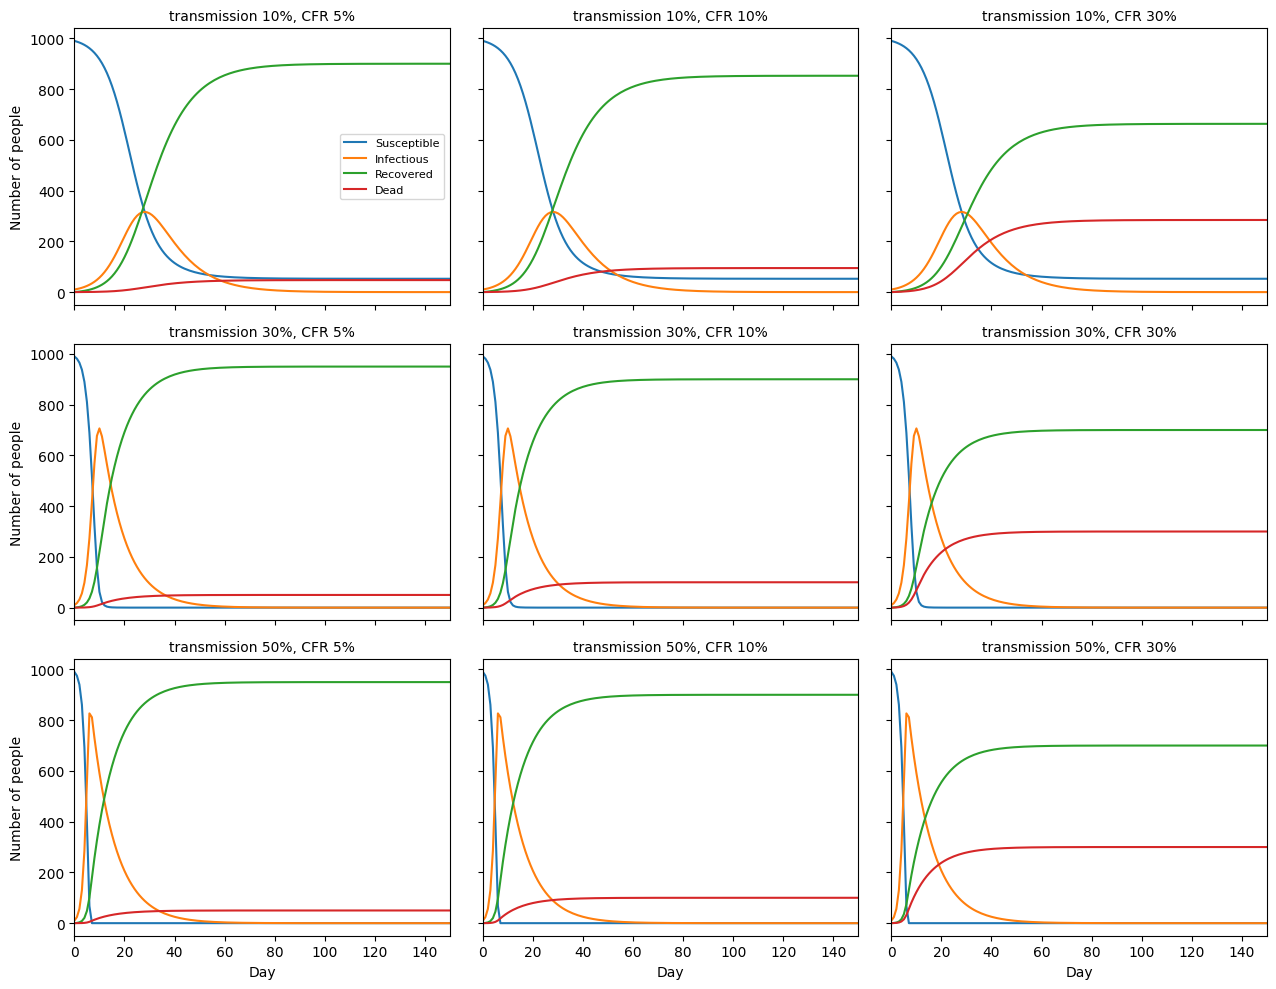

In [ ]:
#@title Exercise 7b (continued) - plotting the SIRD trajectories { display-mode: "form" }

n = 1000
days = 365
gamma = 0.1
contacts = 3
transmissions = [0.1, 0.3, 0.5]
death_rates = [0.05, 0.1, 0.3]

# 3 x 3 grid of panels rather than nine separate figures
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True, sharey=True)

for row, t in enumerate(transmissions):
    beta = contacts * t / n
    for col, d in enumerate(death_rates):
        mu = gamma * d
        gamma_r = gamma * (1 - d)

        S, I, R, D = 990, 10, 0, 0
        S_history, I_history, R_history, D_history = [S], [I], [R], [D]

        for day in range(days):
            new_infections = min(beta * S * I, S)
            new_recoveries = gamma_r * I
            new_deaths = mu * I
            S = S - new_infections
            I = I + new_infections - new_recoveries - new_deaths
            R = R + new_recoveries
            D = D + new_deaths
            S_history.append(S)
            I_history.append(I)
            R_history.append(R)
            D_history.append(D)

        ax = axes[row][col]
        ax.plot(S_history, label="Susceptible")
        ax.plot(I_history, label="Infectious")
        ax.plot(R_history, label="Recovered")
        ax.plot(D_history, label="Dead")
        ax.set_xlim(0, 150)
        ax.set_title(f"transmission {t:.0%}, CFR {d:.0%}", fontsize=10)

axes[0][0].legend(fontsize=8)
for ax in axes[2]:
    ax.set_xlabel("Day")
for row in axes:
    row[0].set_ylabel("Number of people")
plt.tight_layout()
plt.show()

---

**Before you close this tab**: make sure you are in your own copy
(**File → Save a copy in Drive**) or download it
(**File → Download → Download .ipynb**).